# 16 — Voice Activity Detection & Turn-Taking

## Objective

In this notebook, we will explore how voice assistants detect when a user is speaking and when a conversational turn begins or ends.

We will focus on:

- frame-based audio processing;
- Voice Activity Detection (VAD);
- speech vs silence classification;
- start-of-turn detection;
- end-of-turn detection;
- simple barge-in logic.

## Core idea

A voice assistant processes audio in short frames and decides whether each frame contains speech or silence.

Basic pipeline:

Audio Stream
→ Frames
→ Voice Activity Detection
→ Speech / Silence
→ Turn-Taking Logic

## Create a synthetic speech/silence signal

To test Voice Activity Detection, we will create a simple synthetic audio signal containing alternating periods of silence and speech-like activity.

This gives us a controlled example where we already know when speech should be detected.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

sample_rate = 16000

# Durations in seconds
silence_1 = 1.0
speech_1 = 1.5
silence_2 = 0.7
speech_2 = 1.2
silence_3 = 1.0

def tone(duration, frequency=220, amplitude=0.5):
    t = np.linspace(
        0,
        duration,
        int(sample_rate * duration),
        endpoint=False
    )
    return amplitude * np.sin(2 * np.pi * frequency * t)

signal = np.concatenate([
    np.zeros(int(sample_rate * silence_1)),
    tone(speech_1, 220),
    np.zeros(int(sample_rate * silence_2)),
    tone(speech_2, 260),
    np.zeros(int(sample_rate * silence_3))
])

duration = len(signal) / sample_rate

print("Duration:", round(duration, 2), "seconds")
print("Samples:", len(signal))

display(Audio(signal, rate=sample_rate))

Duration: 5.4 seconds
Samples: 86400


## Split the audio into frames

Voice Activity Detection usually analyzes short audio frames instead of the complete signal.

We will use 20 ms frames, which are commonly used in speech processing systems.

In [2]:
frame_duration = 0.020
frame_size = int(sample_rate * frame_duration)

frames = [
    signal[i:i + frame_size]
    for i in range(0, len(signal), frame_size)
]

print("Frame duration:", frame_duration * 1000, "ms")
print("Samples per frame:", frame_size)
print("Number of frames:", len(frames))

Frame duration: 20.0 ms
Samples per frame: 320
Number of frames: 270


## Voice Activity Detection with RMS energy

A simple Voice Activity Detector can use the energy of each audio frame.

Frames with higher RMS energy are classified as speech, while low-energy frames are classified as silence.

In [3]:
rms_values = np.array([
    np.sqrt(np.mean(frame ** 2))
    for frame in frames
])

threshold = 0.05

speech_mask = rms_values > threshold

print("Total frames:", len(frames))
print("Speech frames:", np.sum(speech_mask))
print("Silence frames:", np.sum(~speech_mask))
print("Speech ratio:", round(np.mean(speech_mask) * 100, 2), "%")

Total frames: 270
Speech frames: 135
Silence frames: 135
Speech ratio: 50.0 %


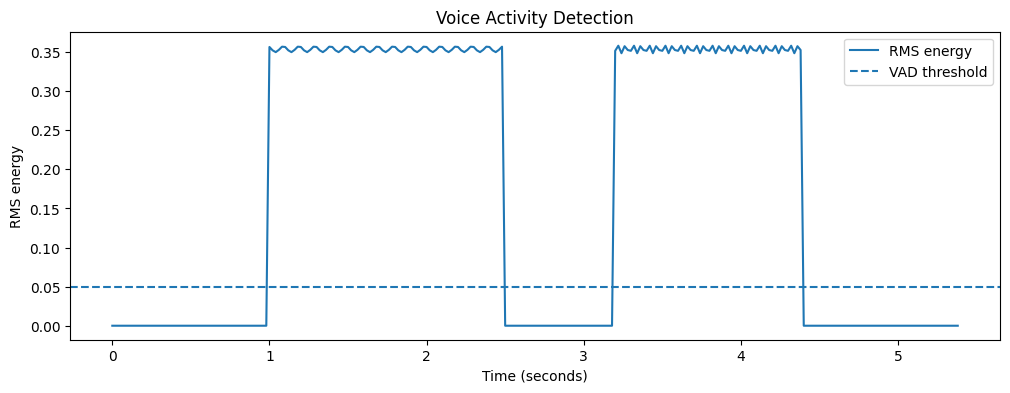

In [4]:
frame_times = np.arange(len(rms_values)) * frame_duration

plt.figure(figsize=(12, 4))

plt.plot(frame_times, rms_values, label="RMS energy")
plt.axhline(threshold, linestyle="--", label="VAD threshold")

plt.xlabel("Time (seconds)")
plt.ylabel("RMS energy")
plt.title("Voice Activity Detection")

plt.legend()
plt.show()

## Start-of-turn and End-of-turn Detection

Voice Activity Detection tells us whether each frame contains speech.

Turn-taking logic uses this information to detect:

- when the user starts speaking;
- when the user stops speaking;
- when a complete conversational turn is ready to be processed.

We will use consecutive speech and silence frames to make these decisions more stable.

In [5]:
min_speech_frames = 3
end_silence_frames = 10

in_turn = False
speech_count = 0
silence_count = 0

turns = []
turn_start = None

for i, is_speech in enumerate(speech_mask):
    
    if is_speech:
        speech_count += 1
        silence_count = 0

        if not in_turn and speech_count >= min_speech_frames:
            in_turn = True
            turn_start = i - min_speech_frames + 1

    else:
        silence_count += 1
        speech_count = 0

        if in_turn and silence_count >= end_silence_frames:
            turn_end = i - end_silence_frames

            turns.append((turn_start, turn_end))

            in_turn = False
            turn_start = None

# Handle a turn that continues until the end
if in_turn:
    turns.append((turn_start, len(speech_mask) - 1))

print("Detected turns:")

for start_frame, end_frame in turns:
    start_time = start_frame * frame_duration
    end_time = end_frame * frame_duration

    print(
        f"Start: {start_time:.2f}s | "
        f"End: {end_time:.2f}s | "
        f"Duration: {end_time - start_time:.2f}s"
    )

Detected turns:
Start: 1.00s | End: 2.48s | Duration: 1.48s
Start: 3.20s | End: 4.38s | Duration: 1.18s


### Turn detection result

The turn-taking logic successfully detected two separate speech segments.

Detected turns:

- Turn 1: 1.00 s → 2.48 s
- Turn 2: 3.20 s → 4.38 s

The system uses consecutive speech frames to detect the beginning of a turn and consecutive silence frames to detect the end of a turn.

This makes the detection more stable than reacting to a single frame.

## Barge-In Detection

Barge-in happens when the user starts speaking while the assistant is still producing a spoken response.

A conversational voice assistant should detect this interruption and stop the current TTS output so it can listen to the user.

Basic logic:

Assistant Speaking
→ VAD detects user speech
→ Interrupt TTS
→ Listen to User

In [6]:
assistant_speaking = True

barge_in_detected = False

for i, is_speech in enumerate(speech_mask):

    if assistant_speaking and is_speech:
        barge_in_time = i * frame_duration
        barge_in_detected = True

        print(
            f"Barge-in detected at {barge_in_time:.2f}s"
        )

        assistant_speaking = False
        break

if not barge_in_detected:
    print("No barge-in detected")

Barge-in detected at 1.00s


## Robust Barge-In Detection

A real voice assistant should not interrupt its response because of a single noisy frame.

To make barge-in detection more stable, we will require several consecutive speech frames before stopping the assistant.

In [7]:
assistant_speaking = True

required_speech_frames = 3
speech_count = 0
barge_in_detected = False

for i, is_speech in enumerate(speech_mask):

    if assistant_speaking:

        if is_speech:
            speech_count += 1
        else:
            speech_count = 0

        if speech_count >= required_speech_frames:
            start_frame = i - required_speech_frames + 1
            barge_in_time = start_frame * frame_duration

            print(
                f"Barge-in detected at {barge_in_time:.2f}s"
            )

            assistant_speaking = False
            barge_in_detected = True
            break

if not barge_in_detected:
    print("No barge-in detected")

Barge-in detected at 1.00s


### Barge-in result

The system detected user speech while the assistant was considered to be speaking.

Instead of reacting to a single frame, the detector required several consecutive speech frames before triggering the interruption.

This makes barge-in detection more robust to short noises or isolated false positives.

## Conclusion

In this notebook, we explored how Voice Activity Detection and turn-taking logic can be used in conversational voice systems.

### What we implemented

- frame-based audio processing;
- RMS-based Voice Activity Detection;
- speech and silence classification;
- start-of-turn detection;
- end-of-turn detection;
- simple barge-in detection;
- robust barge-in using consecutive speech frames.

### Final pipeline

Audio Stream
→ Frames
→ Voice Activity Detection
→ Speech / Silence
→ Turn-Taking Logic
→ Start / End of Turn
→ Barge-In Detection

### Key takeaway

Voice Activity Detection determines whether speech is present, while turn-taking logic decides when a user starts or finishes speaking.

Barge-in detection allows a voice assistant to interrupt its own response when the user starts speaking again, making conversations more natural and responsive.